# HW2：多元線性回歸（Multiple Linear Regression）— CRISP-DM

本 notebook 以同一套流程分析兩個 Kaggle 資料集（原始特徵數皆在 10–20 之間）：

| 題目 | 資料集 | 特徵數 | 目標 |
|---|---|---|---|
| A | [Kaggle Playground S4E5 — Regression with a Flood Prediction Dataset](https://www.kaggle.com/competitions/playground-series-s4e5)（檔案取自 [naiyakhalid/flood-prediction-dataset](https://www.kaggle.com/datasets/naiyakhalid/flood-prediction-dataset)） | 20（數值） | `FloodProbability` |
| B | [Student Performance Factors](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors) | 19（數值＋類別） | `Exam_Score` |

每個題目都依 CRISP-DM 六步驟進行：Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment。

**特徵選擇**比較 5 種方法（SelectKBest、RFE、Sequential Forward Selection、Lasso path、Permutation importance），所有選擇只使用訓練資料；
**模型評估**使用 MAE、MSE、RMSE、R²、Adjusted R²、5-fold CV，並檢查線性回歸的五大假設；
**預測圖**附 95% 信賴區間（CI）與預測區間（PI）。

資料下載方式（需先 `kaggle auth login`）：
```
kaggle datasets download -d naiyakhalid/flood-prediction-dataset -p data/flood-prediction-dataset --unzip
kaggle datasets download -d lainguyn123/student-performance-factors -p data/student-performance-factors --unzip
```

## 0. 環境與共用函式

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.feature_selection import RFE, f_regression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV, lasso_path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
DATA = Path("data")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

In [2]:
class Preprocessor:
    """Fit on training data only: median/mode imputation + one-hot encoding (drop_first)."""

    def fit(self, X: pd.DataFrame):
        self.num_cols = X.select_dtypes(include="number").columns.tolist()
        self.cat_cols = [c for c in X.columns if c not in self.num_cols]
        self.medians = X[self.num_cols].median()
        self.modes = {c: X[c].mode()[0] for c in self.cat_cols}
        self.categories = {c: sorted(X[c].dropna().unique()) for c in self.cat_cols}
        self.columns = self.transform(X).columns.tolist()
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        X = X.copy()
        X[self.num_cols] = X[self.num_cols].fillna(self.medians)
        for c in self.cat_cols:
            X[c] = pd.Categorical(X[c].fillna(self.modes[c]), categories=self.categories[c])
        out = pd.get_dummies(X, columns=self.cat_cols, drop_first=True, dtype=float)
        return out.reindex(columns=getattr(self, "columns", out.columns), fill_value=0.0)


def metrics(y_true, y_pred, n_features):
    n = len(y_true)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2,
        "Adj_R2": 1 - (1 - r2) * (n - 1) / (n - n_features - 1),
        "k": n_features,
    }


def cv_rmse(X, y, cols, cv):
    scores = cross_val_score(LinearRegression(), X[cols], y, cv=cv,
                             scoring="neg_root_mean_squared_error")
    return -scores.mean()

In [3]:
def rank_features(X, y, cv):
    """Return a full ranking (best first) of the columns of X for each selection method."""
    Xs = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns, index=X.index)
    cols = list(X.columns)
    ranks = {}

    # 1) SelectKBest: univariate F-test
    F, _ = f_regression(Xs, y)
    ranks["SelectKBest (F-test)"] = [cols[i] for i in np.argsort(-F)]

    # 2) RFE: recursively drop the smallest |coef| of a standardized OLS
    rfe = RFE(LinearRegression(), n_features_to_select=1).fit(Xs, y)
    ranks["RFE"] = [cols[i] for i in np.argsort(rfe.ranking_)]

    # 3) Sequential Forward Selection: greedily add the feature that lowers CV RMSE most
    chosen, left = [], cols.copy()
    while left:
        best = min(left, key=lambda c: cv_rmse(Xs, y, chosen + [c], cv))
        chosen.append(best)
        left.remove(best)
    ranks["Sequential Forward"] = chosen

    # 4) Lasso path: order in which features enter the model as alpha decreases
    alphas, coefs, _ = lasso_path(Xs.values, y.values, n_alphas=200)
    entry = [np.argmax(np.abs(coefs[i]) > 0) if np.any(coefs[i]) else len(alphas) for i in range(len(cols))]
    ranks["Lasso path"] = [cols[i] for i in np.argsort(entry, kind="stable")]

    # 5) Permutation importance of the full OLS on a held-out part of the training data
    Xa, Xb, ya, yb = train_test_split(Xs, y, test_size=0.25, random_state=SEED)
    pi = permutation_importance(LinearRegression().fit(Xa, ya), Xb, yb,
                                n_repeats=5, random_state=SEED, scoring="r2")
    ranks["Permutation importance"] = [cols[i] for i in np.argsort(-pi.importances_mean)]
    return ranks


def k_curves(X, y, ranks, cv):
    rows = []
    for method, order in ranks.items():
        for k in range(1, len(order) + 1):
            rows.append({"method": method, "k": k, "cv_rmse": cv_rmse(X, y, order[:k], cv)})
    return pd.DataFrame(rows)


def choose_k(curves, tol=0.005):
    """Smallest k (over all methods) whose CV RMSE is within `tol` of the overall best."""
    best = curves.cv_rmse.min()
    ok = curves[curves.cv_rmse <= best * (1 + tol)].sort_values(["k", "cv_rmse"])
    return ok.iloc[0]

In [4]:
def plot_k_curves(curves, chosen, title):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.lineplot(data=curves, x="k", y="cv_rmse", hue="method", marker="o", ax=ax)
    ax.axvline(chosen.k, color="grey", ls="--", lw=1)
    ax.annotate(f"chosen k={chosen.k}\n({chosen.method})", (chosen.k, chosen.cv_rmse),
                xytext=(10, 25), textcoords="offset points", fontsize=9,
                arrowprops=dict(arrowstyle="->", color="grey"))
    ax.set(title=title, xlabel="number of features k", ylabel="5-fold CV RMSE (train)")
    plt.tight_layout()
    plt.show()


def fit_ols(X, y):
    return sm.OLS(y, sm.add_constant(X, has_constant="add")).fit()


def check_assumptions(ols, X, max_points=5000):
    """Five classical assumptions: linearity, independence, homoscedasticity, normality, no multicollinearity."""
    resid, fitted = ols.resid, ols.fittedvalues
    idx = np.random.default_rng(SEED).choice(len(resid), min(max_points, len(resid)), replace=False)
    r, f = resid.iloc[idx], fitted.iloc[idx]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    sns.regplot(x=f, y=r, lowess=True, scatter_kws=dict(s=6, alpha=.35),
                line_kws=dict(color="crimson"), ax=axes[0])
    axes[0].axhline(0, color="k", lw=.8)
    axes[0].set(title="Residuals vs Fitted (linearity / homoscedasticity)", xlabel="fitted", ylabel="residual")
    sm.qqplot(r, line="s", ax=axes[1], markersize=3, alpha=.4)
    axes[1].set_title("Normal Q-Q (normality)")
    sns.histplot(r, kde=True, ax=axes[2])
    axes[2].set_title("Residual distribution")
    plt.tight_layout()
    plt.show()

    Xc = sm.add_constant(X, has_constant="add")
    bp_p = het_breuschpagan(resid, Xc)[1]
    jb_p = jarque_bera(resid)[1]
    dw = durbin_watson(resid)
    vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                    index=X.columns, name="VIF").sort_values(ascending=False)
    summary = pd.DataFrame({
        "assumption": ["1. Linearity", "2. Independence", "3. Homoscedasticity", "4. Normality", "5. No multicollinearity"],
        "test": ["Residuals vs Fitted (LOWESS ≈ 0)", "Durbin-Watson", "Breusch-Pagan p-value",
                 "Jarque-Bera p-value", "max VIF"],
        "value": [np.nan, dw, bp_p, jb_p, vif.max()],
        "rule of thumb": ["flat red line", "≈ 2 (1.5–2.5)", "> 0.05", "> 0.05", "< 5 (< 10)"],
    })
    return summary, vif


def prediction_frame(ols, X, alpha=0.05):
    sf = ols.get_prediction(sm.add_constant(X, has_constant="add")).summary_frame(alpha=alpha)
    return sf.rename(columns={"mean": "pred", "mean_ci_lower": "ci_lo", "mean_ci_upper": "ci_hi",
                              "obs_ci_lower": "pi_lo", "obs_ci_upper": "pi_hi"})


def plot_prediction(pf, y_true, title, n=120):
    """Sorted prediction plot with 95% CI and 95% PI bands + actual-vs-predicted scatter."""
    df = pf.assign(actual=np.asarray(y_true))
    s = df.sample(min(n, len(df)), random_state=SEED).sort_values("pred").reset_index(drop=True)
    coverage = ((df.actual >= df.pi_lo) & (df.actual <= df.pi_hi)).mean()

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw=dict(width_ratios=[1.7, 1]))
    ax = axes[0]
    ax.fill_between(s.index, s.pi_lo, s.pi_hi, color="tab:blue", alpha=.15, label="95% prediction interval")
    ax.fill_between(s.index, s.ci_lo, s.ci_hi, color="tab:blue", alpha=.45, label="95% confidence interval")
    ax.plot(s.index, s.pred, color="tab:blue", lw=1.6, label="prediction")
    ax.scatter(s.index, s.actual, s=12, color="tab:orange", zorder=3, label="actual")
    ax.set(title=f"{title}: {len(s)} random test samples sorted by prediction",
           xlabel="test sample (sorted)", ylabel="target")
    ax.legend(loc="upper left", fontsize=9)

    ax = axes[1]
    sub = df.sample(min(4000, len(df)), random_state=SEED)
    ax.scatter(sub.actual, sub.pred, s=6, alpha=.35)
    lo, hi = sub[["actual", "pred"]].min().min(), sub[["actual", "pred"]].max().max()
    ax.plot([lo, hi], [lo, hi], color="crimson", lw=1)
    ax.set(title=f"Actual vs Predicted (PI coverage on test = {coverage:.1%})", xlabel="actual", ylabel="predicted")
    plt.tight_layout()
    plt.show()
    return coverage

In [5]:
def run_modeling(X_tr, y_tr, X_te, y_te, selected):
    """Compare OLS (all), OLS (selected), RidgeCV, LassoCV on the same split."""
    scaler = StandardScaler().fit(X_tr)
    Xs_tr, Xs_te = scaler.transform(X_tr), scaler.transform(X_te)
    models = {
        "OLS (all features)": (LinearRegression().fit(X_tr, y_tr), X_tr, X_te),
        f"OLS (selected k={len(selected)})": (LinearRegression().fit(X_tr[selected], y_tr), X_tr[selected], X_te[selected]),
        "RidgeCV (all, scaled)": (RidgeCV(alphas=np.logspace(-3, 3, 25)).fit(Xs_tr, y_tr), Xs_tr, Xs_te),
        "LassoCV (all, scaled)": (LassoCV(cv=5, random_state=SEED, alphas=50).fit(Xs_tr, y_tr), Xs_tr, Xs_te),
    }
    cv = KFold(5, shuffle=True, random_state=SEED)
    rows = []
    for name, (m, A_tr, A_te) in models.items():
        k = A_tr.shape[1] if name.startswith(("OLS", "Ridge")) else int(np.sum(m.coef_ != 0))
        row = {"model": name, **metrics(y_te, m.predict(A_te), k)}
        row["CV_RMSE (train)"] = -cross_val_score(m, A_tr, y_tr, cv=cv, scoring="neg_root_mean_squared_error").mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index("model"), models

---
# 題目 A：洪水機率預測（Kaggle Playground Series S4E5）

## A-1. Business Understanding
- **問題**：依據一個地區的季風強度、都市化、排水系統、堤防品質等 20 項指標，預測該地區的洪水發生機率 `FloodProbability`（0–1 的連續值）。
- **用途**：讓防災單位依預測結果排序高風險地區、分配預算（例如優先改善排水或堤防）。
- **成功標準**：Kaggle 本競賽的評分指標為 **R²**；我們以測試集 R²、RMSE 作為主要指標，並用預測區間說明單筆預測的不確定性。
- **為何不用 50k 的 `flood.csv`**：初步檢查發現 `flood.csv` 的目標值是 20 個特徵的精確線性組合（OLS 測試 R² = 1.000、RMSE = 0），不具建模與不確定性分析的意義，因此改用競賽的 `train.csv`（1,117,957 筆，含雜訊）。

## A-2. Data Understanding

In [6]:
A_TARGET = "FloodProbability"
flood = pd.read_csv(DATA / "flood-prediction-dataset" / "train.csv")
flood_test = pd.read_csv(DATA / "flood-prediction-dataset" / "test.csv")   # Kaggle test set (no target)
print("train:", flood.shape, " kaggle test:", flood_test.shape)
print("missing values:", int(flood.isna().sum().sum()), " duplicated rows:", int(flood.drop(columns="id").duplicated().sum()))
flood.head()

train: (1117957, 22)  kaggle test: (745305, 21)


missing values: 0  duplicated rows: 0


,id,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,0,5,8,5,8,6,4,4,3,3,...,5,3,3,5,4,7,5,7,3,0.445
1,1,6,7,4,4,8,8,3,5,4,...,7,2,0,3,5,3,3,4,3,0.450
2,2,6,5,6,7,3,7,1,5,4,...,7,3,7,5,6,8,2,3,3,0.530
3,3,3,4,6,5,4,8,4,7,6,...,2,4,7,4,4,6,5,7,5,0.535
4,4,5,3,2,6,4,4,3,3,3,...,2,2,6,6,4,1,2,3,5,0.415


In [7]:
flood.drop(columns="id").describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
MonsoonIntensity,1117957.0,4.921,2.056,0.000,3.00,5.000,6.00,16.000
TopographyDrainage,1117957.0,4.927,2.094,0.000,3.00,5.000,6.00,18.000
RiverManagement,1117957.0,4.955,2.072,0.000,4.00,5.000,6.00,16.000
Deforestation,1117957.0,4.942,2.052,0.000,4.00,5.000,6.00,17.000
Urbanization,1117957.0,4.943,2.083,0.000,3.00,5.000,6.00,17.000
ClimateChange,1117957.0,4.934,2.058,0.000,3.00,5.000,6.00,17.000
DamsQuality,1117957.0,4.956,2.083,0.000,4.00,5.000,6.00,16.000
Siltation,1117957.0,4.928,2.066,0.000,3.00,5.000,6.00,16.000
AgriculturalPractices,1117957.0,4.943,2.069,0.000,3.00,5.000,6.00,16.000
Encroachments,1117957.0,4.949,2.083,0.000,4.00,5.000,6.00,18.000


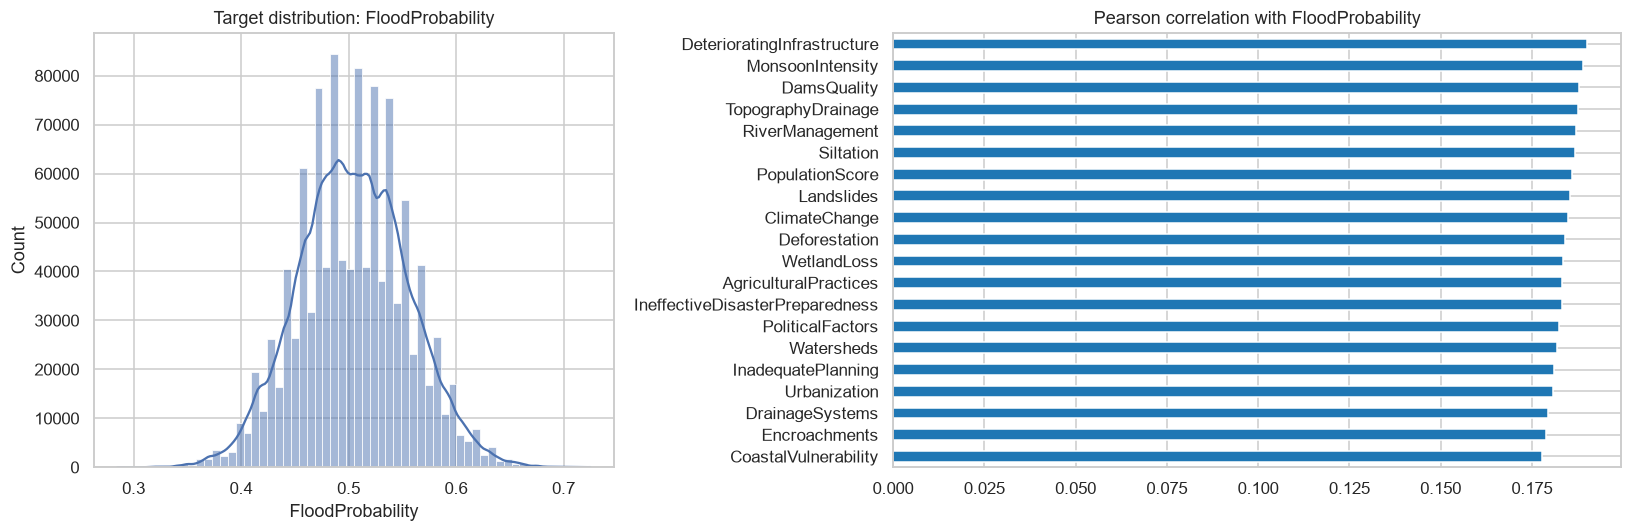

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw=dict(width_ratios=[1, 1.4]))
sns.histplot(flood[A_TARGET], bins=60, kde=True, ax=axes[0])
axes[0].set_title("Target distribution: FloodProbability")
corr = flood.drop(columns="id").corr()[A_TARGET].drop(A_TARGET).sort_values()
corr.plot.barh(ax=axes[1], color="tab:blue")
axes[1].set_title("Pearson correlation with FloodProbability")
plt.tight_layout()
plt.show()

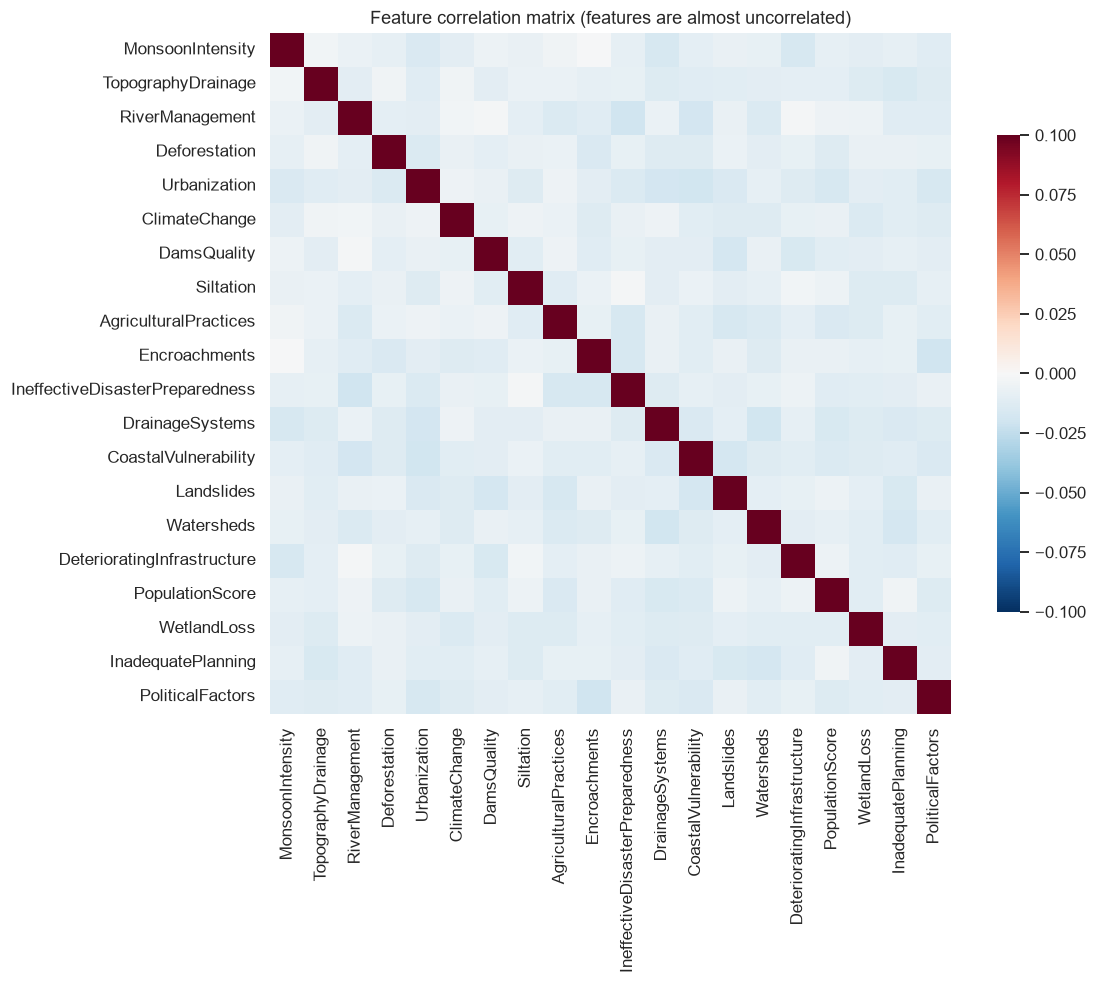

In [9]:
plt.figure(figsize=(11, 9))
sns.heatmap(flood.drop(columns=["id", A_TARGET]).sample(100_000, random_state=SEED).corr(),
            cmap="RdBu_r", center=0, vmin=-.1, vmax=.1, square=True, cbar_kws=dict(shrink=.7))
plt.title("Feature correlation matrix (features are almost uncorrelated)")
plt.tight_layout()
plt.show()

**觀察**
- 20 個特徵皆為 0–18 的整數評分，無缺失值、無重複列；目標值近似常態，90% 落在 0.42–0.59。
- 每個特徵與目標的相關係數都在 0.178–0.190 之間，**沒有單一主導特徵**；特徵之間幾乎不相關（|r| < 0.02），共線性風險低。
- 推論：這是「多個小效應相加」的資料，特徵選擇可能會傾向保留大部分特徵。

## A-3. Data Preparation

In [10]:
XA = flood.drop(columns=["id", A_TARGET])
yA = flood[A_TARGET]
XA_tr_raw, XA_te_raw, yA_tr, yA_te = train_test_split(XA, yA, test_size=0.2, random_state=SEED)

prepA = Preprocessor().fit(XA_tr_raw)          # all numeric, no missing: a no-op here, kept for a uniform pipeline
XA_tr, XA_te = prepA.transform(XA_tr_raw), prepA.transform(XA_te_raw)

# feature selection runs on a 60k subsample of the TRAINING split (speed); final models use the full training split
sel_idx = XA_tr.sample(60_000, random_state=SEED).index
XA_sel, yA_sel = XA_tr.loc[sel_idx], yA_tr.loc[sel_idx]
print("train", XA_tr.shape, "test", XA_te.shape, "selection subsample", XA_sel.shape)

train (894365, 20) test (223592, 20) selection subsample (60000, 20)


- 移除 `id`（流水號，無預測意義）。
- 80/20 切分訓練／測試集（`random_state=42`），之後所有特徵選擇、標準化、超參數調整**只用訓練集**，避免資料洩漏。
- 資料無缺失、無類別欄，前處理器在此不改變資料；保留它是為了與題目 B 共用同一套流程。

## A-4. Modeling — 特徵選擇

In [11]:
cvA = KFold(5, shuffle=True, random_state=SEED)
ranksA = rank_features(XA_sel, yA_sel, cvA)
pd.DataFrame({m: r for m, r in ranksA.items()}, index=pd.RangeIndex(1, len(XA_tr.columns) + 1, name="rank"))

,SelectKBest (F-test),RFE,Sequential Forward,Lasso path,Permutation importance
rank,,,,,
1,PopulationScore,PopulationScore,PopulationScore,MonsoonIntensity,Watersheds
2,TopographyDrainage,TopographyDrainage,TopographyDrainage,TopographyDrainage,PopulationScore
3,Landslides,Landslides,Landslides,ClimateChange,CoastalVulnerability
4,DeterioratingInfrastructure,Watersheds,Watersheds,DamsQuality,PoliticalFactors
5,MonsoonIntensity,WetlandLoss,WetlandLoss,Landslides,DeterioratingInfrastructure
6,Watersheds,DeterioratingInfrastructure,DeterioratingInfrastructure,Watersheds,WetlandLoss
7,ClimateChange,DamsQuality,AgriculturalPractices,DeterioratingInfrastructure,Urbanization
8,WetlandLoss,RiverManagement,MonsoonIntensity,PopulationScore,Encroachments
9,DamsQuality,AgriculturalPractices,DamsQuality,WetlandLoss,DamsQuality


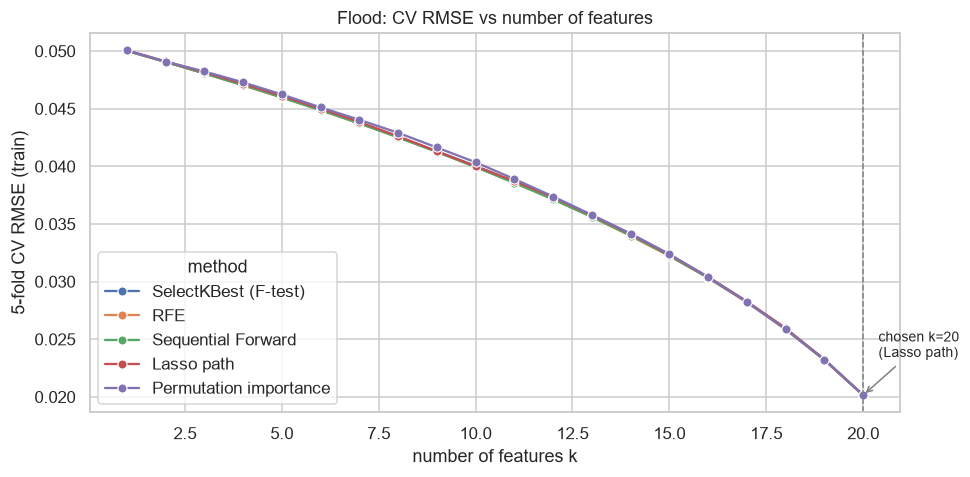

chosen: Lasso path, k=20, CV RMSE=0.02015
selected features: ['MonsoonIntensity', 'TopographyDrainage', 'ClimateChange', 'DamsQuality', 'Landslides', 'Watersheds', 'DeterioratingInfrastructure', 'PopulationScore', 'WetlandLoss', 'RiverManagement', 'Deforestation', 'Siltation', 'AgriculturalPractices', 'Encroachments', 'IneffectiveDisasterPreparedness', 'PoliticalFactors', 'Urbanization', 'DrainageSystems', 'CoastalVulnerability', 'InadequatePlanning']


In [12]:
curvesA = k_curves(XA_sel, yA_sel, ranksA, cvA)
chosenA = choose_k(curvesA)
selectedA = ranksA[chosenA.method][: chosenA.k]
plot_k_curves(curvesA, chosenA, "Flood: CV RMSE vs number of features")
print(f"chosen: {chosenA.method}, k={chosenA.k}, CV RMSE={chosenA.cv_rmse:.5f}")
print("selected features:", selectedA)

In [13]:
curvesA.pivot(index="k", columns="method", values="cv_rmse").loc[[5, 10, 14, 15, 17, 18, 19, 20]].round(5)

method,Lasso path,Permutation importance,RFE,SelectKBest (F-test),Sequential Forward
k,,,,,
5,0.04610,0.04623,0.04598,0.04600,0.04598
10,0.04000,0.04035,0.03997,0.04003,0.03993
14,0.03412,0.03417,0.03396,0.03412,0.03399
15,0.03232,0.03238,0.03223,0.03233,0.03225
17,0.02827,0.02823,0.02819,0.02827,0.02824
18,0.02596,0.02586,0.02585,0.02590,0.02586
19,0.02320,0.02320,0.02320,0.02326,0.02320
20,0.02015,0.02015,0.02015,0.02015,0.02015


**特徵選擇結論**：5 種方法的排序不同，但 CV RMSE 曲線都隨 k 增加而一路下降，到 k=20 都沒有趨平（k=19→20 仍從 0.0232 降到 0.0202，約 13%）。
選擇規則為「CV RMSE 在最佳值 0.5% 以內的最小 k」，結果是 **k=20，全部保留**。這與 A-2 的觀察一致：每個特徵都貢獻同樣大小的訊號，刪掉任何一個都會讓誤差明顯上升。
特徵選擇在這裡的價值是「證明不能刪」，而不是刪出更小的模型。

## A-4. Modeling — 模型比較

In [14]:
resA, modelsA = run_modeling(XA_tr, yA_tr, XA_te, yA_te, selectedA)
resA.round(5)

,MAE,MSE,RMSE,R2,Adj_R2,k,CV_RMSE (train)
model,,,,,,,
OLS (all features),0.01579,0.0004,0.02008,0.84488,0.84486,20,0.0201
OLS (selected k=20),0.01579,0.0004,0.02008,0.84488,0.84486,20,0.0201
"RidgeCV (all, scaled)",0.01579,0.0004,0.02008,0.84488,0.84486,20,0.0201
"LassoCV (all, scaled)",0.01580,0.0004,0.02008,0.84488,0.84486,20,0.0201


In [15]:
olsA = fit_ols(XA_tr[selectedA], yA_tr)
print(olsA.summary().tables[0])
coefA = pd.DataFrame({"coef": olsA.params, "std err": olsA.bse, "t": olsA.tvalues, "p-value": olsA.pvalues,
                      "CI 2.5%": olsA.conf_int()[0], "CI 97.5%": olsA.conf_int()[1]})
coefA.round(5)

                            OLS Regression Results                            
Dep. Variable:       FloodProbability   R-squared:                       0.845
Model:                            OLS   Adj. R-squared:                  0.845
Method:                 Least Squares   F-statistic:                 2.437e+05
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:32:54   Log-Likelihood:             2.2255e+06
No. Observations:              894365   AIC:                        -4.451e+06
Df Residuals:                  894344   BIC:                        -4.451e+06
Df Model:                          20                                         
Covariance Type:            nonrobust                                         


,coef,std err,t,p-value,CI 2.5%,CI 97.5%
const,-0.05333,0.00025,-210.29559,0.0,-0.05382,-0.05283
MonsoonIntensity,0.00561,0.00001,543.01776,0.0,0.00559,0.00563
TopographyDrainage,0.00565,0.00001,555.42244,0.0,0.00563,0.00567
ClimateChange,0.00566,0.00001,547.15276,0.0,0.00564,0.00568
DamsQuality,0.00565,0.00001,553.37343,0.0,0.00563,0.00567
Landslides,0.00564,0.00001,551.25967,0.0,0.00562,0.00566
Watersheds,0.00565,0.00001,552.89543,0.0,0.00563,0.00567
DeterioratingInfrastructure,0.00562,0.00001,545.33493,0.0,0.00560,0.00564
PopulationScore,0.00568,0.00001,554.21688,0.0,0.00566,0.00570
WetlandLoss,0.00564,0.00001,548.09924,0.0,0.00562,0.00566


## A-5. Evaluation

MAE        0.01579
MSE        0.00040
RMSE       0.02008
R2         0.84488
Adj_R2     0.84486
k         20.00000


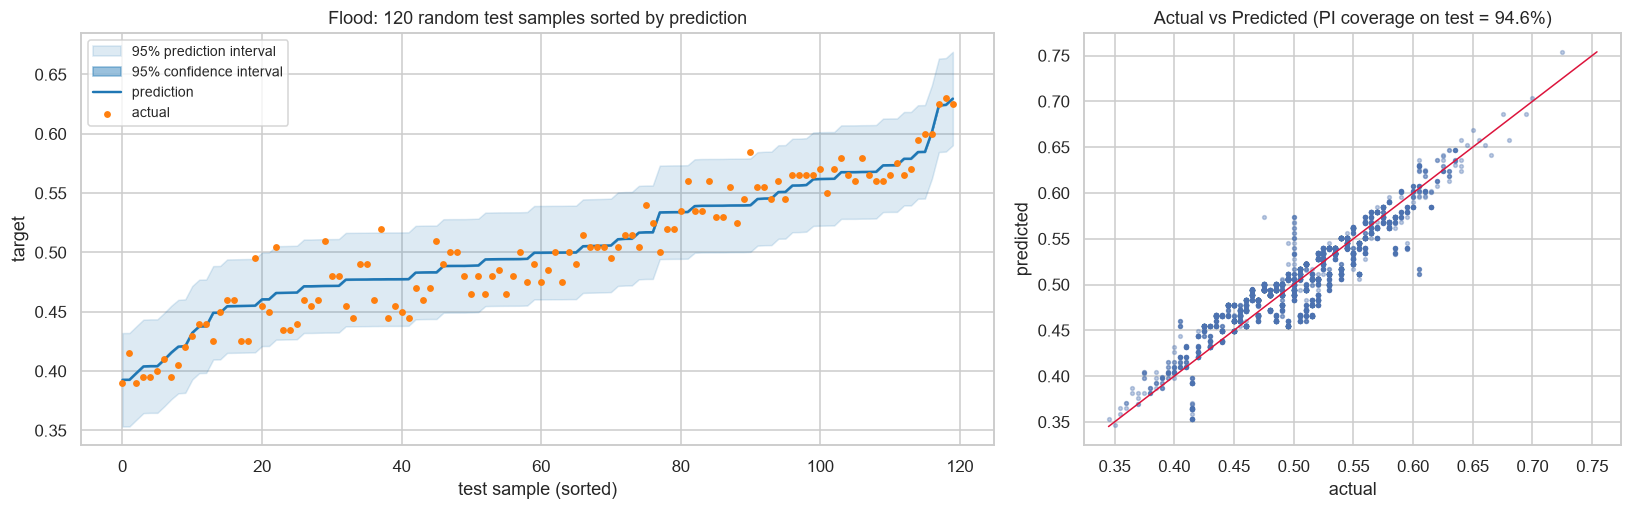

In [16]:
pfA = prediction_frame(olsA, XA_te[selectedA])
evalA = pd.Series(metrics(yA_te, pfA.pred, len(selectedA))).round(5)
print(evalA.to_string())
coverageA = plot_prediction(pfA, yA_te, "Flood")

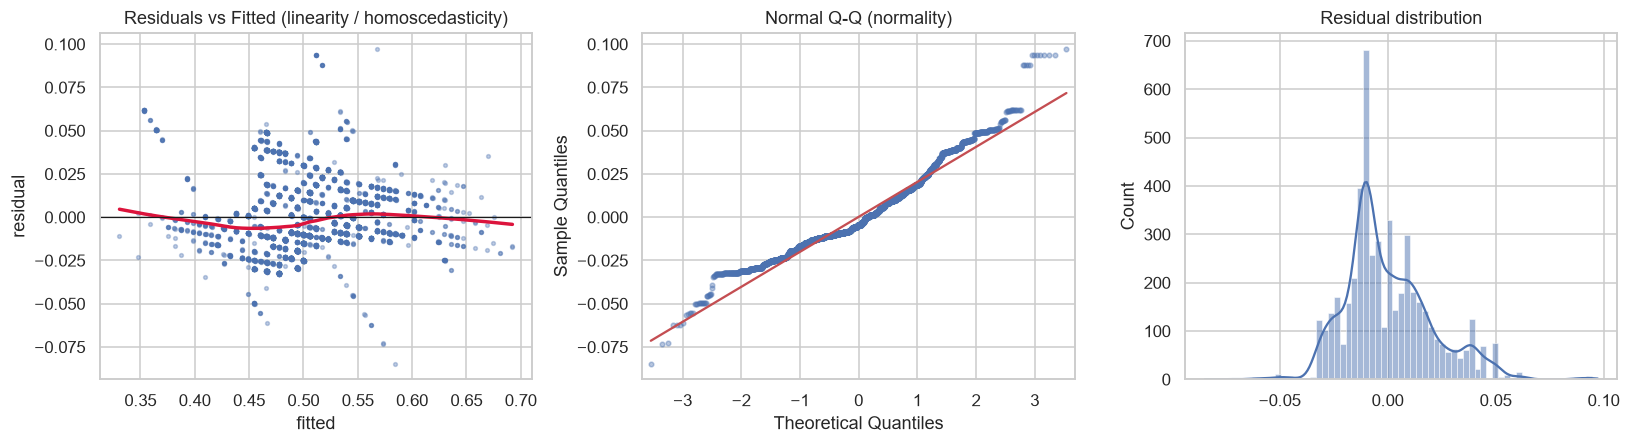

,assumption,test,value,rule of thumb
0,1. Linearity,Residuals vs Fitted (LOWESS ≈ 0),NaN,flat red line
1,2. Independence,Durbin-Watson,2.000391,≈ 2 (1.5–2.5)
2,3. Homoscedasticity,Breusch-Pagan p-value,0.000000,> 0.05
3,4. Normality,Jarque-Bera p-value,0.000000,> 0.05
4,5. No multicollinearity,max VIF,1.003672,< 5 (< 10)


In [17]:
assumpA, vifA = check_assumptions(olsA, XA_tr[selectedA])
assumpA

**評估結論（題目 A）**
- 測試集 R² = 0.845、RMSE = 0.020；訓練集 CV RMSE 與測試集一致，沒有過擬合。OLS、Ridge、Lasso 結果幾乎相同（特徵不共線，正則化沒有幫助）。
- **係數的發現**：20 個係數全部落在 0.0056–0.0057，信賴區間彼此重疊。也就是說模型實際上是
  `FloodProbability ≈ 0.00565 × (20 個特徵總和) − 0.053`——洪水機率只取決於「風險評分總和」，各因素同等重要。
- 預測區間在測試集上的實際覆蓋率為 94.6%，接近名目的 95%，區間寬度估計合理；信賴區間（平均值的不確定性）因樣本數大而窄到幾乎看不見。
- 假設檢查：Durbin-Watson ≈ 2（獨立）、VIF ≈ 1（無共線性）。殘差圖的 LOWESS 線呈輕微 S 形、Q-Q 圖兩端偏離，Breusch-Pagan 與 Jarque-Bera 在近 90 萬筆樣本下 p 值為 0——大樣本會讓微小偏差也顯著，但也提示線性模型沒有捕捉到的非線性。Kaggle 高分解法多加入「特徵總和」、標準差、排序後的統計量等工程特徵，正是處理這部分。

### A-5. Kaggle 提交結果與名次
A-6 產生的 `outputs/submission_flood.csv`（Kaggle 測試集 745,305 筆）已於 2026-10-17 提交到競賽（late submission，submission id 57316306），Kaggle 回傳的分數如下。
名次以分數對照當天下載的 Public 排行榜換算（競賽已結束，late submission 不會列入正式排行榜）。
排行榜下載指令：`kaggle competitions leaderboard -c playground-series-s4e5 --download -p outputs`

,R2
local test split (A-5),0.84488
Kaggle Public,0.84458
Kaggle Private,0.84426
leaderboard #1,0.86943
leaderboard median,0.85856


equivalent public rank: 1850 / 2794 teams (top 66.2%)


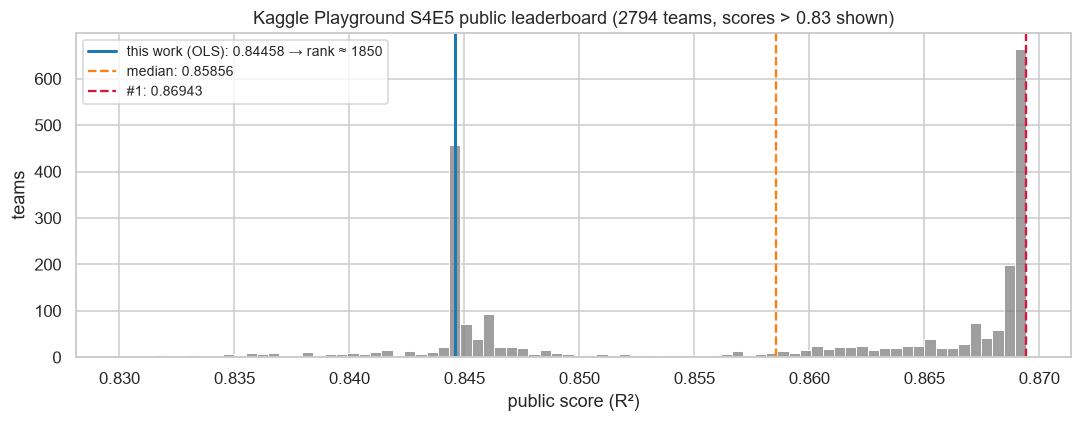

In [18]:
KAGGLE_PUBLIC, KAGGLE_PRIVATE = 0.84458, 0.84426   # scores returned by Kaggle for submission 57316306

lb = pd.read_csv(sorted((OUT / "lb").glob("*publicleaderboard*.csv"))[-1])
equiv_rank = int((lb.Score > KAGGLE_PUBLIC).sum()) + 1
display(pd.DataFrame({
    "R2": {"local test split (A-5)": evalA["R2"], "Kaggle Public": KAGGLE_PUBLIC, "Kaggle Private": KAGGLE_PRIVATE,
           "leaderboard #1": lb.Score.max(), "leaderboard median": lb.Score.median()},
}).round(5))
print(f"equivalent public rank: {equiv_rank} / {len(lb)} teams (top {equiv_rank / len(lb):.1%})")

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(lb.Score[lb.Score > 0.83], bins=80, ax=ax, color="tab:grey")
ax.axvline(KAGGLE_PUBLIC, color="tab:blue", lw=2, label=f"this work (OLS): {KAGGLE_PUBLIC} → rank ≈ {equiv_rank}")
ax.axvline(lb.Score.median(), color="tab:orange", ls="--", label=f"median: {lb.Score.median():.5f}")
ax.axvline(lb.Score.max(), color="crimson", ls="--", label=f"#1: {lb.Score.max():.5f}")
ax.set(title=f"Kaggle Playground S4E5 public leaderboard ({len(lb)} teams, scores > 0.83 shown)",
       xlabel="public score (R²)", ylabel="teams")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

**Kaggle 結果解讀**
- Kaggle 的 Public／Private 分數（0.84458／0.84426）與本機測試集 R²（0.845）幾乎相同，證實本機的評估方式可信，模型沒有過擬合。
- 換算名次約為 2,794 隊中的第 1,850 名。與第 1 名（0.86943）相差約 0.025，差距來自模型形式而非調參。
- 排行榜分數呈**兩群**：約 450 隊集中在 0.8446 附近——正是本作業的分數，代表這是「20 個原始特徵＋線性模型」的天花板；
  另約 660 隊集中在 0.869，多為加入「20 個特徵總和」、標準差、排序統計量等工程特徵，再用 GBDT／神經網路集成的解法，處理線性模型抓不到的非線性。
- 這與 A-5 的係數發現一致：目標值主要由特徵總和決定，因此以總和為核心的特徵工程能一舉跨到上面那一群。

## A-6. Deployment

In [19]:
def predict_with_interval(ols, prep, cols, new_raw: pd.DataFrame, alpha=0.05):
    """Predict new raw samples (same schema as training) with CI and PI."""
    X = prep.transform(new_raw)[cols]
    return prediction_frame(ols, X, alpha)[["pred", "ci_lo", "ci_hi", "pi_lo", "pi_hi"]]

def save_model(path, prep, cols, ols):
    """Save prep + features + OLS without the training data statsmodels keeps (~800 MB for Flood)."""
    ols.remove_data()   # params/covariance stay, so get_prediction (CI/PI) still works
    joblib.dump({"prep": prep, "features": cols, "ols": ols}, path)

save_model(OUT / "flood_model.joblib", prepA, selectedA, olsA)
print(f"flood_model.joblib: {(OUT / 'flood_model.joblib').stat().st_size / 1e3:.0f} KB")

example = XA_te_raw.head(3)
display(predict_with_interval(olsA, prepA, selectedA, example).assign(actual=yA_te.head(3).values).round(4))

# Kaggle submission (metric: R2). Refit the selected-feature OLS on ALL labelled rows first.
ols_full = fit_ols(prepA.transform(XA)[selectedA], yA)
sub = pd.DataFrame({"id": flood_test["id"],
                    A_TARGET: ols_full.predict(sm.add_constant(prepA.transform(flood_test.drop(columns="id"))[selectedA], has_constant="add"))})
sub.to_csv(OUT / "submission_flood.csv", index=False)
print("saved", OUT / "submission_flood.csv", sub.shape)

flood_model.joblib: 7171 KB


,pred,ci_lo,ci_hi,pi_lo,pi_hi,actual
1105809,0.5339,0.5337,0.5341,0.4945,0.5733,0.560
442591,0.5849,0.5847,0.5852,0.5455,0.6243,0.575
5434,0.5226,0.5224,0.5227,0.4832,0.5620,0.510


saved outputs\submission_flood.csv (745305, 2)


- 模型（前處理器＋選定特徵＋OLS）存成 `outputs/flood_model.joblib`，`predict_with_interval()` 可對新資料輸出預測值與 95% CI / PI。
- `outputs/submission_flood.csv` 可用以下指令提交到 Kaggle 取得分數與名次（需先在競賽頁按 *Join Competition*）：
  `kaggle competitions submit -c playground-series-s4e5 -f outputs/submission_flood.csv -m "MLR OLS"`

---
# 題目 B：學生考試成績預測（Student Performance Factors）

## B-1. Business Understanding
- **問題**：依據學生的讀書時數、出席率、家長參與、睡眠、家庭收入、師資品質等 19 項因素，預測期末考成績 `Exam_Score`。
- **用途**：學校可提早找出可能表現不佳的學生，並了解「哪些可改變的因素（出席、讀書時數、輔導）」影響最大，作為輔導資源分配依據。
- **成功標準**：測試集 RMSE（單位為分數，易解釋）與 R²；同時重視係數的可解釋性。

## B-2. Data Understanding

In [20]:
B_TARGET = "Exam_Score"
student = pd.read_csv(DATA / "student-performance-factors" / "StudentPerformanceFactors.csv")
print(student.shape)
print("missing values per column:\n", student.isna().sum()[lambda s: s > 0])
student.head()

(6607, 20)
missing values per column:
 Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [21]:
num_cols_B = student.select_dtypes(include="number").columns.drop(B_TARGET).tolist()
cat_cols_B = [c for c in student.columns if c not in num_cols_B + [B_TARGET]]
print(f"{len(num_cols_B)} numeric features:", num_cols_B)
print(f"{len(cat_cols_B)} categorical features:", cat_cols_B)
student.describe().T.round(2)

6 numeric features: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
13 categorical features: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.98,5.99,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.98,11.55,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6607.0,7.03,1.47,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,75.07,14.40,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6607.0,1.49,1.23,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6607.0,2.97,1.03,0.0,2.0,3.0,4.0,6.0
Exam_Score,6607.0,67.24,3.89,55.0,65.0,67.0,69.0,101.0


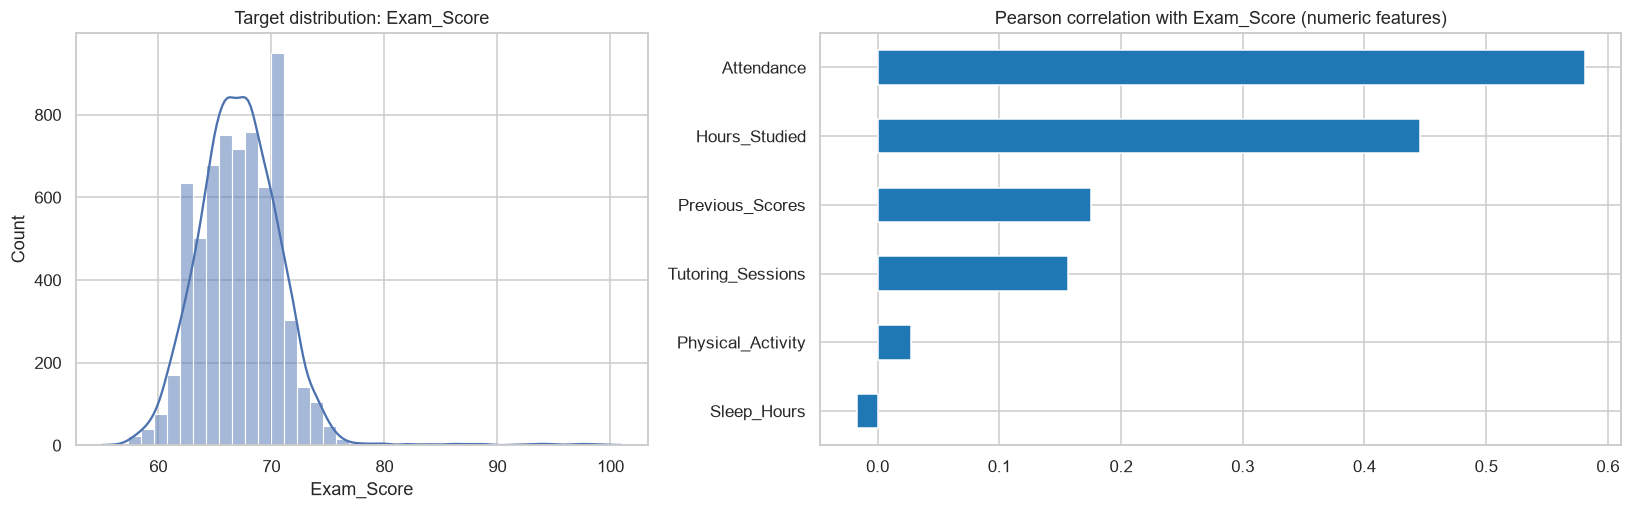

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw=dict(width_ratios=[1, 1.4]))
sns.histplot(student[B_TARGET], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Target distribution: Exam_Score")
student[num_cols_B + [B_TARGET]].corr()[B_TARGET].drop(B_TARGET).sort_values().plot.barh(ax=axes[1], color="tab:blue")
axes[1].set_title("Pearson correlation with Exam_Score (numeric features)")
plt.tight_layout()
plt.show()

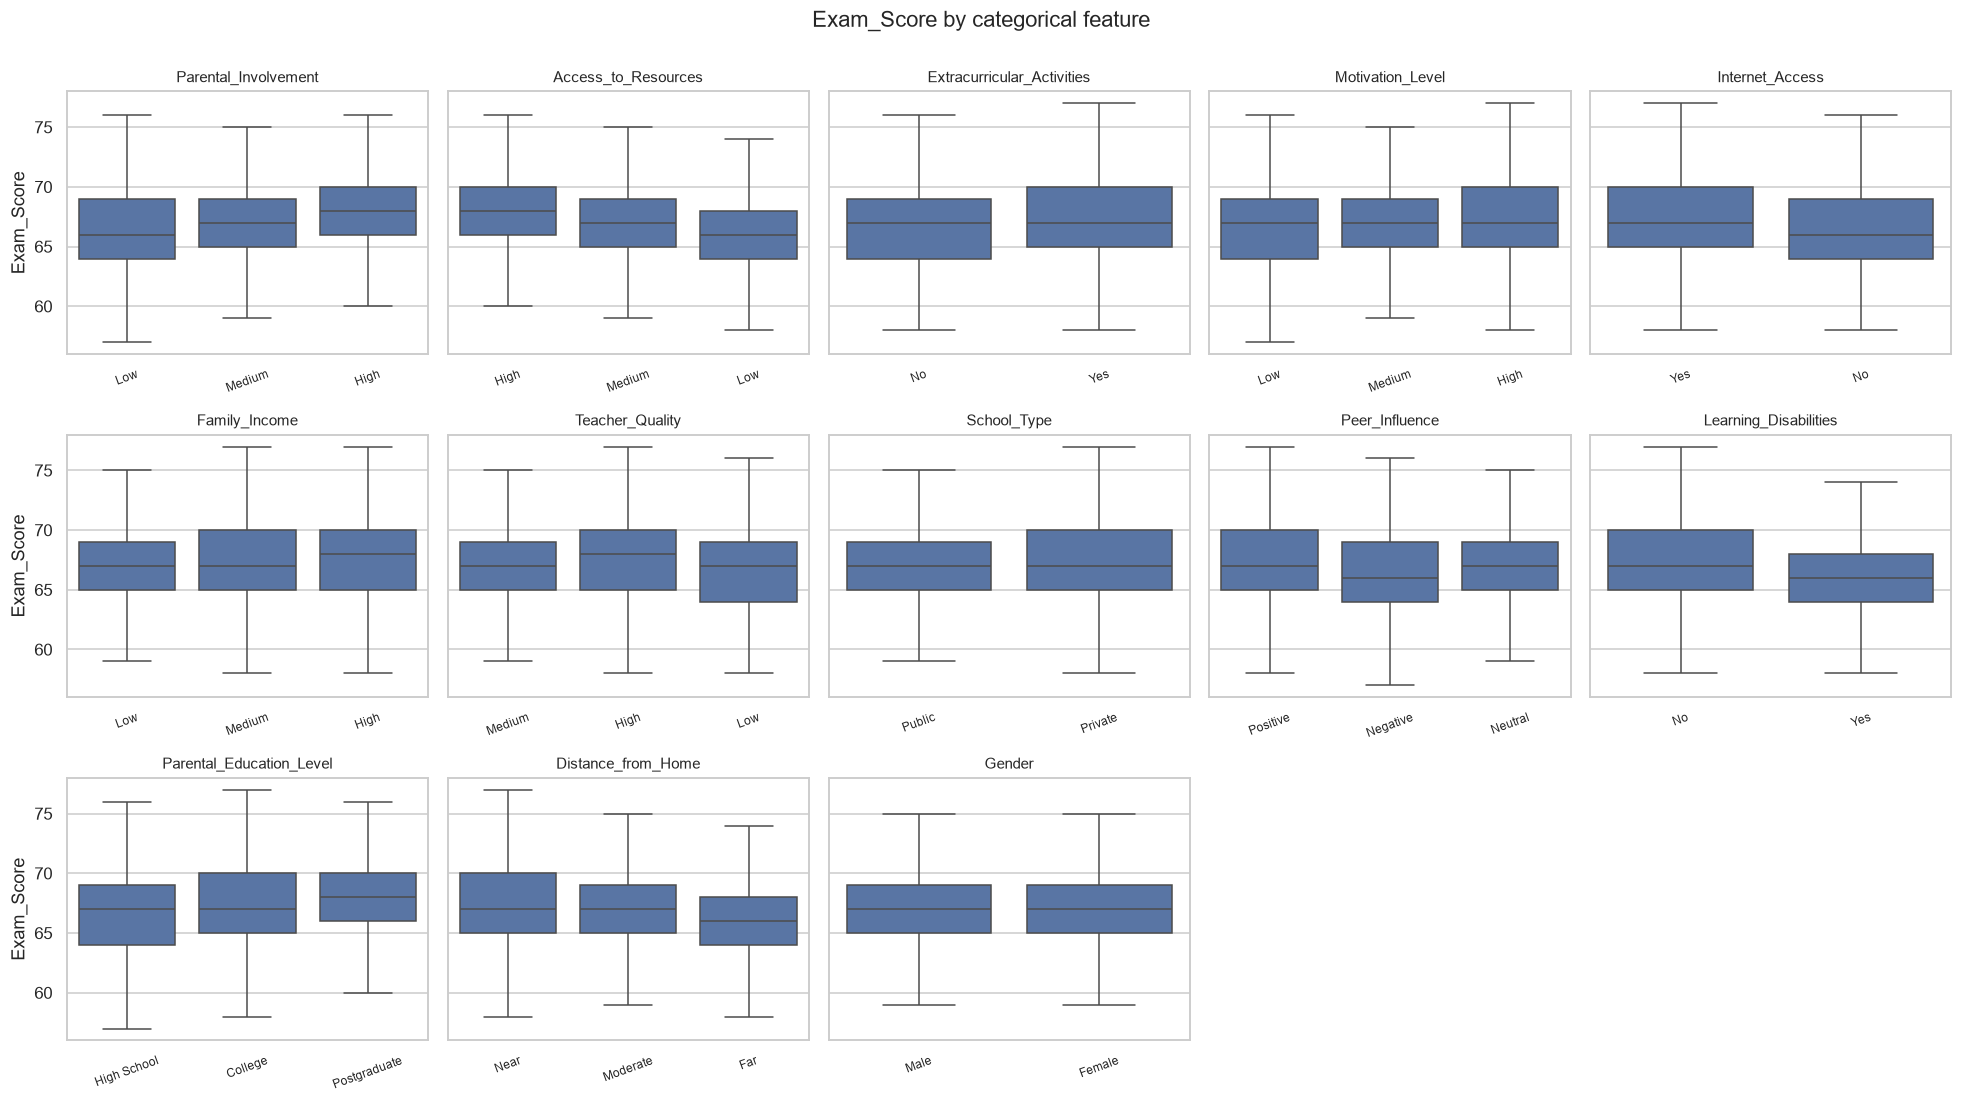

In [23]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10), sharey=True)
for ax, c in zip(axes.flat, cat_cols_B):
    sns.boxplot(data=student, x=c, y=B_TARGET, ax=ax, showfliers=False)
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=8, rotation=20)
for ax in axes.flat[len(cat_cols_B):]:
    ax.set_visible(False)
plt.suptitle("Exam_Score by categorical feature", y=1.0)
plt.tight_layout()
plt.show()

**觀察**
- 6,607 筆、19 個特徵（6 個數值、13 個類別），`Teacher_Quality`、`Parental_Education_Level`、`Distance_from_Home` 有少量缺失（共 235 格）。
- `Attendance`（r≈0.58）與 `Hours_Studied`（r≈0.45）是最強的數值因素；`Sleep_Hours`、`Physical_Activity` 幾乎無關。
- 類別特徵中 `Access_to_Resources`、`Parental_Involvement` 的高／低組差距明顯；`Gender`、`School_Type` 差異很小。
- 目標值 90% 落在 62–73 分，右尾有少數高分離群值（80–101 分），可能影響殘差常態性。
- 資料品質：有 1 筆 `Exam_Score` = 101，超過滿分 100。只有 1 筆、不影響結論，因此保留並在此註明。

## B-3. Data Preparation

In [24]:
XB = student.drop(columns=B_TARGET)
yB = student[B_TARGET]
XB_tr_raw, XB_te_raw, yB_tr, yB_te = train_test_split(XB, yB, test_size=0.2, random_state=SEED)

prepB = Preprocessor().fit(XB_tr_raw)
XB_tr, XB_te = prepB.transform(XB_tr_raw), prepB.transform(XB_te_raw)
print("train", XB_tr.shape, "test", XB_te.shape)
print("encoded columns:", XB_tr.columns.tolist())

train (5285, 27) test (1322, 27)
encoded columns: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Parental_Involvement_Low', 'Parental_Involvement_Medium', 'Access_to_Resources_Low', 'Access_to_Resources_Medium', 'Extracurricular_Activities_Yes', 'Motivation_Level_Low', 'Motivation_Level_Medium', 'Internet_Access_Yes', 'Family_Income_Low', 'Family_Income_Medium', 'Teacher_Quality_Low', 'Teacher_Quality_Medium', 'School_Type_Public', 'Peer_Influence_Neutral', 'Peer_Influence_Positive', 'Learning_Disabilities_Yes', 'Parental_Education_Level_High School', 'Parental_Education_Level_Postgraduate', 'Distance_from_Home_Moderate', 'Distance_from_Home_Near', 'Gender_Male']


- 80/20 切分後，**只用訓練集**計算補值（數值欄用中位數、類別欄用眾數）與類別水準。
- 類別欄做 one-hot 編碼並 `drop_first`（避免虛擬變數陷阱），19 個原始特徵展開為上方列出的欄位。
- 測試集套用同一個前處理器；遇到訓練集沒有的類別時編為全 0（即基準類別）。

## B-4. Modeling — 特徵選擇

In [25]:
cvB = KFold(5, shuffle=True, random_state=SEED)
ranksB = rank_features(XB_tr, yB_tr, cvB)
pd.DataFrame({m: r for m, r in ranksB.items()}, index=pd.RangeIndex(1, XB_tr.shape[1] + 1, name="rank")).head(15)

,SelectKBest (F-test),RFE,Sequential Forward,Lasso path,Permutation importance
rank,,,,,
1,Attendance,Attendance,Attendance,Attendance,Attendance
2,Hours_Studied,Hours_Studied,Hours_Studied,Hours_Studied,Hours_Studied
3,Previous_Scores,Previous_Scores,Previous_Scores,Previous_Scores,Parental_Involvement_Low
4,Tutoring_Sessions,Tutoring_Sessions,Tutoring_Sessions,Tutoring_Sessions,Access_to_Resources_Low
5,Access_to_Resources_Low,Access_to_Resources_Low,Access_to_Resources_Low,Access_to_Resources_Low,Previous_Scores
6,Parental_Involvement_Low,Parental_Involvement_Low,Parental_Involvement_Low,Parental_Involvement_Low,Tutoring_Sessions
7,Parental_Education_Level_Postgraduate,Parental_Involvement_Medium,Parental_Involvement_Medium,Family_Income_Low,Family_Income_Low
8,Learning_Disabilities_Yes,Access_to_Resources_Medium,Access_to_Resources_Medium,Peer_Influence_Positive,Access_to_Resources_Medium
9,Parental_Education_Level_High School,Family_Income_Low,Peer_Influence_Positive,Parental_Education_Level_Postgraduate,Peer_Influence_Positive


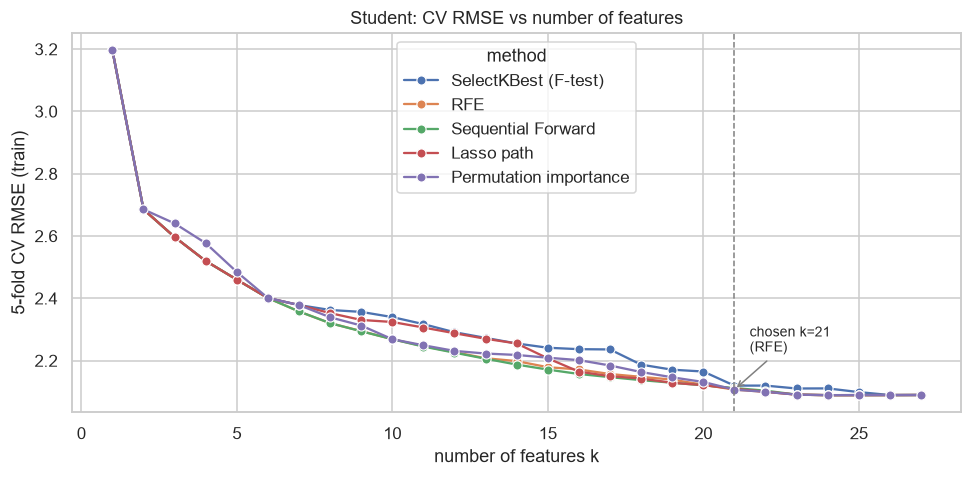

chosen: RFE, k=21, CV RMSE=2.1067
selected features: ['Attendance', 'Hours_Studied', 'Previous_Scores', 'Tutoring_Sessions', 'Access_to_Resources_Low', 'Parental_Involvement_Low', 'Parental_Involvement_Medium', 'Access_to_Resources_Medium', 'Family_Income_Low', 'Peer_Influence_Positive', 'Parental_Education_Level_High School', 'Extracurricular_Activities_Yes', 'Distance_from_Home_Near', 'Family_Income_Medium', 'Motivation_Level_Low', 'Teacher_Quality_Low', 'Teacher_Quality_Medium', 'Peer_Influence_Neutral', 'Motivation_Level_Medium', 'Learning_Disabilities_Yes', 'Internet_Access_Yes']
dropped features: ['Distance_from_Home_Moderate', 'Gender_Male', 'Parental_Education_Level_Postgraduate', 'Physical_Activity', 'School_Type_Public', 'Sleep_Hours']


In [26]:
curvesB = k_curves(XB_tr, yB_tr, ranksB, cvB)
chosenB = choose_k(curvesB, tol=0.01)
selectedB = ranksB[chosenB.method][: chosenB.k]
plot_k_curves(curvesB, chosenB, "Student: CV RMSE vs number of features")
print(f"chosen: {chosenB.method}, k={chosenB.k}, CV RMSE={chosenB.cv_rmse:.4f}")
print("selected features:", selectedB)
dropped = sorted(set(XB_tr.columns) - set(selectedB))
print("dropped features:", dropped)

**特徵選擇結論**：5 種方法的前 6 名幾乎相同（出席率、讀書時數、前次成績、輔導次數、資源、家長參與）；
k = 7–20 之間，Sequential Forward、RFE 這類多變量方法比只看單變量的 SelectKBest 誤差更低。
CV RMSE 在前 6 個特徵加入後快速下降，之後趨於平坦。採「CV RMSE 在最佳值 1% 以內的最小 k」，選出 RFE 的 **k=21**（27 個編碼欄位刪掉 6 個）。
被刪掉的是 `Gender`、`School_Type`、`Sleep_Hours`、`Physical_Activity` 等幾乎無影響的特徵，以及 `Distance_from_Home_Moderate`、`Parental_Education_Level_Postgraduate` 兩個效應較小的類別水準。

## B-4. Modeling — 模型比較

In [27]:
resB, modelsB = run_modeling(XB_tr, yB_tr, XB_te, yB_te, selectedB)
resB.round(4)

,MAE,MSE,RMSE,R2,Adj_R2,k,CV_RMSE (train)
model,,,,,,,
OLS (all features),0.4524,3.2560,1.8044,0.7696,0.7648,27,2.0895
OLS (selected k=21),0.5430,3.3306,1.8250,0.7644,0.7606,21,2.1067
"RidgeCV (all, scaled)",0.4522,3.2554,1.8043,0.7697,0.7649,27,2.0895
"LassoCV (all, scaled)",0.4516,3.2540,1.8039,0.7698,0.7650,27,2.0896


In [28]:
olsB = fit_ols(XB_tr[selectedB], yB_tr)
print(olsB.summary().tables[0])
coefB = pd.DataFrame({"coef": olsB.params, "std err": olsB.bse, "t": olsB.tvalues, "p-value": olsB.pvalues,
                      "CI 2.5%": olsB.conf_int()[0], "CI 97.5%": olsB.conf_int()[1]})
coefB.sort_values("t", key=abs, ascending=False).round(4)

                            OLS Regression Results                            
Dep. Variable:             Exam_Score   R-squared:                       0.712
Model:                            OLS   Adj. R-squared:                  0.711
Method:                 Least Squares   F-statistic:                     620.3
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:33:35   Log-Likelihood:                -11430.
No. Observations:                5285   AIC:                         2.290e+04
Df Residuals:                    5263   BIC:                         2.305e+04
Df Model:                          21                                         
Covariance Type:            nonrobust                                         


,coef,std err,t,p-value,CI 2.5%,CI 97.5%
const,42.7434,0.3255,131.3191,0.0,42.1053,43.3815
Attendance,0.1990,0.0025,78.8585,0.0,0.1940,0.2039
Hours_Studied,0.2937,0.0048,60.6046,0.0,0.2842,0.3032
Access_to_Resources_Low,-2.1070,0.0842,-25.0368,0.0,-2.2720,-1.9420
Previous_Scores,0.0492,0.0020,24.3417,0.0,0.0452,0.0531
Parental_Involvement_Low,-1.9970,0.0843,-23.7032,0.0,-2.1622,-1.8318
Tutoring_Sessions,0.5107,0.0235,21.7010,0.0,0.4646,0.5569
Parental_Involvement_Medium,-1.0615,0.0677,-15.6835,0.0,-1.1942,-0.9288
Access_to_Resources_Medium,-1.0179,0.0672,-15.1563,0.0,-1.1496,-0.8863
Family_Income_Low,-1.1026,0.0805,-13.6971,0.0,-1.2605,-0.9448


## B-5. Evaluation

MAE        0.5430
MSE        3.3306
RMSE       1.8250
R2         0.7644
Adj_R2     0.7606
k         21.0000


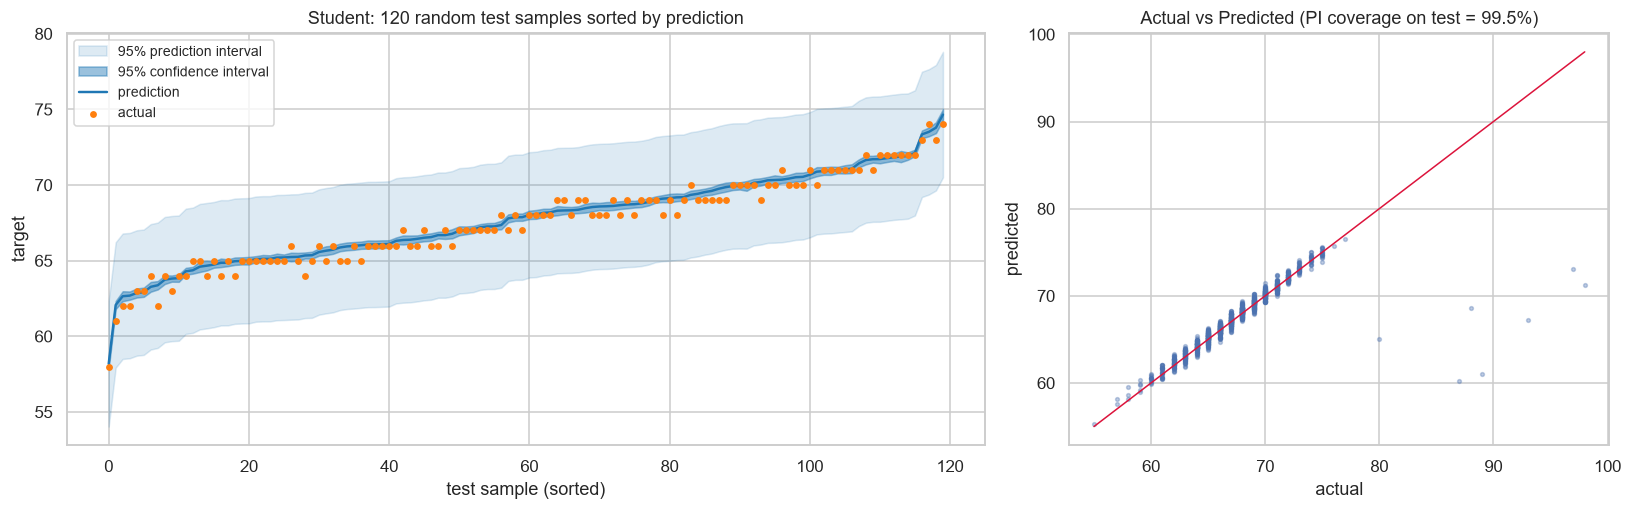

In [29]:
pfB = prediction_frame(olsB, XB_te[selectedB])
evalB = pd.Series(metrics(yB_te, pfB.pred, len(selectedB))).round(4)
print(evalB.to_string())
coverageB = plot_prediction(pfB, yB_te, "Student")

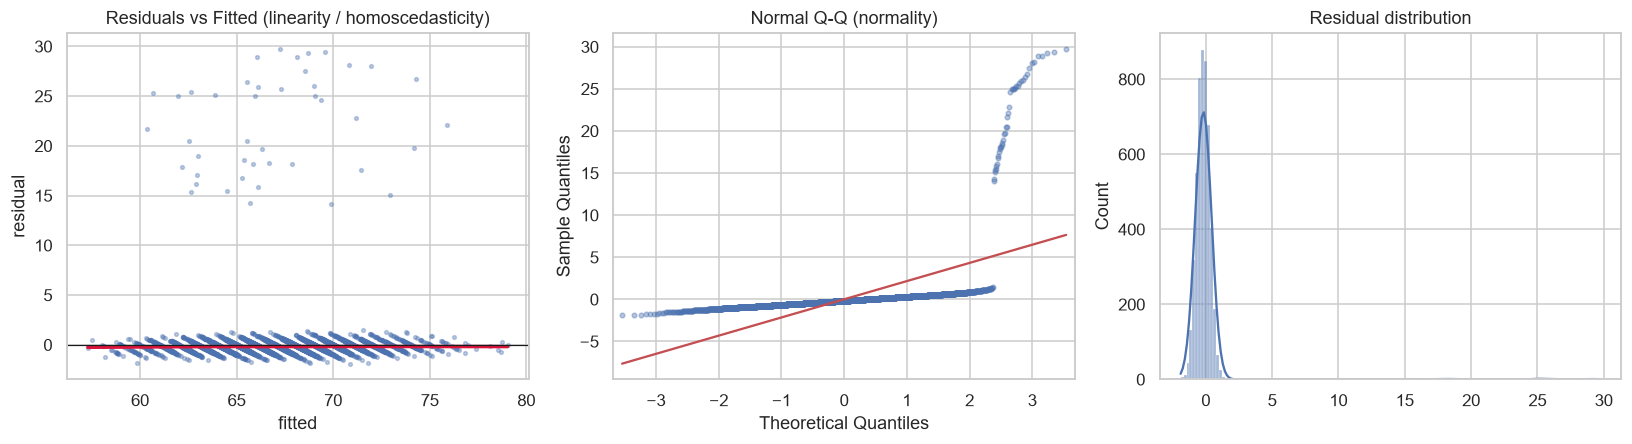

,assumption,test,value,rule of thumb
0,1. Linearity,Residuals vs Fitted (LOWESS ≈ 0),NaN,flat red line
1,2. Independence,Durbin-Watson,1.948786,≈ 2 (1.5–2.5)
2,3. Homoscedasticity,Breusch-Pagan p-value,0.852709,> 0.05
3,4. Normality,Jarque-Bera p-value,0.000000,> 0.05
4,5. No multicollinearity,max VIF,1.860180,< 5 (< 10)


Family_Income_Medium           1.86
Family_Income_Low              1.86
Motivation_Level_Medium        1.77
Motivation_Level_Low           1.77
Peer_Influence_Neutral         1.75
Peer_Influence_Positive        1.75
Parental_Involvement_Low       1.36
Parental_Involvement_Medium    1.36
Name: VIF, dtype: float64

In [30]:
assumpB, vifB = check_assumptions(olsB, XB_tr[selectedB])
display(assumpB)
vifB.head(8).round(2)

In [31]:
residB = yB_te - pfB.pred
print("test residual quantiles:\n", residB.quantile([.01, .05, .5, .95, .99]).round(2).to_string())
print(f"share of test samples with |residual| > 5 points: {(residB.abs() > 5).mean():.1%}")

test residual quantiles:
 0.01   -1.26
0.05   -0.95
0.50   -0.18
0.95    0.68
0.99    1.12
share of test samples with |residual| > 5 points: 0.5%


**評估結論（題目 B）**
- **精簡的代價**：精簡模型（k=21）的測試 RMSE 1.825、R² 0.764，與全特徵 OLS（1.804、0.770）相近；但 MAE 從 0.452 升到 0.543（約 +20%）。
  原因是刪掉的兩個類別水準（`Distance_from_Home_Moderate`、`Parental_Education_Level_Postgraduate`）其實有小而真實的效應——刪掉一個虛擬變數等於把該水準併入基準類別。
  若重視準確度可改用全特徵模型；若重視精簡與解釋，k=21 的損失很小。Ridge／Lasso 沒有更好，表示誤差不是來自過擬合。
- **誤差幾乎全來自離群值**：測試集 98% 的殘差落在 ±1.3 分以內，|殘差| > 5 分的只有 0.5%。從 Actual vs Predicted 圖可見，少數學生實際 80–100 分、模型只預測 60–73 分。
  也就是說，一般學生的分數幾乎就是各因素的線性加總，R² 停在約 0.77 主要是這些離群值造成的。
- **預測區間過寬**：測試集覆蓋率是 99.5%，高於名目的 95%。OLS 的 PI 假設殘差常態，離群值把殘差標準差撐大到約 1.8，所以對一般學生而言 PI（約 ±4 分）過於保守。
- 假設檢查：DW = 1.95（獨立）、Breusch-Pagan p = 0.85（變異數同質）、max VIF = 1.86（無共線性）皆通過；
  Jarque-Bera p ≈ 0 不通過，Q-Q 圖右上翹——同樣是那群高分離群值造成的長右尾。

## B-6. Deployment

In [32]:
save_model(OUT / "student_model.joblib", prepB, selectedB, olsB)

new_student = pd.DataFrame([{
    "Hours_Studied": 25, "Attendance": 90, "Parental_Involvement": "High", "Access_to_Resources": "Medium",
    "Extracurricular_Activities": "Yes", "Sleep_Hours": 7, "Previous_Scores": 80, "Motivation_Level": "Medium",
    "Internet_Access": "Yes", "Tutoring_Sessions": 2, "Family_Income": "Medium", "Teacher_Quality": "High",
    "School_Type": "Public", "Peer_Influence": "Positive", "Physical_Activity": 3, "Learning_Disabilities": "No",
    "Parental_Education_Level": "College", "Distance_from_Home": "Near", "Gender": "Female",
}])
predict_with_interval(olsB, prepB, selectedB, new_student).round(2)

,pred,ci_lo,ci_hi,pi_lo,pi_hi
0,74.01,73.79,74.24,69.87,78.15


- 模型存成 `outputs/student_model.joblib`；`predict_with_interval()` 對一位新學生輸出預測分數與 95% CI / PI。
- 解讀：CI 是「同樣條件學生的**平均**成績」範圍，PI 是「**這一位**學生」成績的範圍，因此 PI 寬得多。

---
# 總結：兩個題目比較

In [33]:
summary = pd.DataFrame({
    "A: Flood": {**evalA.to_dict(), "PI coverage (test)": coverageA, "selection method": chosenA.method,
                 "original features": XA.shape[1]},
    "B: Student": {**evalB.to_dict(), "PI coverage (test)": coverageB, "selection method": chosenB.method,
                   "original features": XB.shape[1]},
})
summary

,A: Flood,B: Student
MAE,0.01579,0.543
MSE,0.0004,3.3306
RMSE,0.02008,1.825
R2,0.84488,0.7644
Adj_R2,0.84486,0.7606
k,20.0,21.0
PI coverage (test),0.946112,0.994705
selection method,Lasso path,RFE
original features,20,19


| | 題目 A：Flood | 題目 B：Student |
|---|---|---|
| 資料特性 | 20 個互不相關、效應相近的數值特徵；百萬筆 | 數值＋類別混合、有缺失值；6,607 筆 |
| 前處理重點 | 幾乎不需要 | 補值、one-hot 編碼 |
| 特徵選擇結果 | 20 個全部保留（每個特徵貢獻相同） | 27 個編碼欄位保留 21 個，刪除無影響的特徵 |
| 測試集 R² / RMSE | 0.845 / 0.020 | 0.764 / 1.83 分 |
| 95% PI 實際覆蓋率 | 94.6%（準確） | 99.5%（過寬，受離群值影響） |
| 線性模型的限制 | 輕微非線性，需要工程特徵才能再提升 | 約 0.5% 高分離群值拉低 R²、撐寬 PI |

同一套「前處理 → 特徵選擇 → OLS → 假設檢查 → CI/PI」流程能套用到結構完全不同的兩份資料，也是之後網頁版「輸入任意 CSV」功能的基礎。